# Final Notebook 04 — CHIRPS v2/v3 RNL: Pentad & Monthly Calibration and Time-Series Diagnostics

**PH3043 | University of Colombo | Six stations | 1981–2000**

### Research question
Does direct calibration of CHIRPS pentad/monthly rainfall totals outperform (i) uncorrected CHIRPS and (ii) totals accumulated from corrected daily rainfall, when models are evaluated on later years? Separately, how well do **gauge-only** monthly forecasting baselines perform, and do SARIMA residuals satisfy serial-independence diagnostics?

### Distinguish two fundamentally different tasks
- **Retrospective calibration (primary):** CHIRPS rainfall for the *target interval is available*. Correct the interval total. This does **not** forecast future rain.
- **Forecasting (separate demonstration):** only gauge rainfall observed *before the forecast origin* is available. Compare historical persistence, seasonal naive, ETS and SARIMA for a genuine 24-month-ahead forecast. Do not call these directly comparable to a same-month CHIRPS calibration without explaining different information availability.

**Study rules:** train/validation folds: 1981–86→1987–88; 1981–88→1989–90; 1981–90→1991–92; 1981–92→1993–94. No 1995–2000 use for model choice. The earlier project inspected those historical-test years; report this limitation. All models are trained strictly on dates before their validation folds.

### Hypotheses
- **H5:** Direct pentad/monthly calibration can lower error relative to raw CHIRPS or the sum of daily corrections. Improvements are *station- and scale-dependent*; do not assume all candidates improve.
- **H6:** Seasonal structure and temporal dependence may improve the modelling of monthly rainfall. We evaluate this via forecast skill and residual diagnostics, not merely an ADF/KPSS p-value.

**Expected output:** figures (PNG and PDF) and CSVs under `results/Final_04_Scale_Specific_Calibration/run_###/`. No data download or new GEE extraction.

## 0. Setup — one location-aware cell, reproducible output folder

The `*.xls` copy in the review environment was CSV-formatted text. On your computer the canonical processed file is `.csv`. We support either extension but always use `pd.read_csv` for this particular dataset. `statsmodels` is needed for ADF, KPSS, Ljung–Box, ETS and SARIMA. If missing, install into the **current kernel** using `%pip install statsmodels`.

In [1]:
from pathlib import Path
import warnings, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

STATIONS=['Badulla','Colombo','Galle','Kandy','Nuwaraeliya','Puttalam']
PRODUCTS={'CHIRPS v2':'CHIRPS_mm','CHIRPS v3 RNL':'CHIRPS_V3_mm'}
FOLDS=[('1981-01-01','1986-12-31','1987-01-01','1988-12-31'),
       ('1981-01-01','1988-12-31','1989-01-01','1990-12-31'),
       ('1981-01-01','1990-12-31','1991-01-01','1992-12-31'),
       ('1981-01-01','1992-12-31','1993-01-01','1994-12-31')]
PROJECT_ROOT=None
for p in (Path.cwd(), *Path.cwd().parents):
    if (p/'data').is_dir() and (p/'notebooks').is_dir():
        PROJECT_ROOT=p; break
if PROJECT_ROOT is None: PROJECT_ROOT=Path.cwd()
DATA_PATH=None # specify a full path here only if your file is elsewhere
if DATA_PATH is None:
    candidates=[PROJECT_ROOT/'data'/'processed'/'Ground_CHIRPS_V2_V3_Paired_1981_2000.csv',
                PROJECT_ROOT/'data'/'processed'/'Ground_CHIRPS_V2_V3_Paired_1981_2000.xls',
                Path.cwd()/'Ground_CHIRPS_V2_V3_Paired_1981_2000.csv',
                Path('/mnt/data/Ground_CHIRPS_V2_V3_Paired_1981_2000.xls')]
    DATA_PATH=next((p for p in candidates if p.is_file()),None)
if DATA_PATH is None: raise FileNotFoundError('Set DATA_PATH to data/processed/Ground_CHIRPS_V2_V3_Paired_1981_2000.csv')
raw=pd.read_csv(DATA_PATH,parse_dates=['Date'])
raw=raw.sort_values(['Station','Date']).reset_index(drop=True)
assert raw[['Station','Date']].duplicated().sum()==0
assert set(STATIONS)==set(raw.Station.unique())
assert raw.Date.max().year==2000
assert (raw[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']]>=0).all().all()
BASE=PROJECT_ROOT/'results'/'Final_04_Scale_Specific_Calibration'
i=1
while (BASE/f'run_{i:03d}').exists():i+=1
OUT=BASE/f'run_{i:03d}'
FIGDIR=OUT/'figures';TABDIR=OUT/'tables'
FIGDIR.mkdir(parents=True);TABDIR.mkdir(parents=True)
print('Dataset:',DATA_PATH,'\nRoot:',PROJECT_ROOT,'\nOutput:',OUT)
print('Rows:',len(raw),'\nDates:',raw.Date.min().date(),raw.Date.max().date())

def save_fig(fig,name):
    fig.savefig(FIGDIR/f'{name}.png',dpi=220,bbox_inches='tight')
    fig.savefig(FIGDIR/f'{name}.pdf',bbox_inches='tight')


Dataset: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_V2_V3_Paired_1981_2000.csv 
Root: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach 
Output: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_04_Scale_Specific_Calibration\run_001
Rows: 43737 
Dates: 1981-01-01 2000-12-31


## 1. Define scales and verify complete intervals

A calendar pentad is days 1–5, 6–10, 11–15, 16–20, 21–25, and **26–month-end**. The last interval can be 3, 4, 5 or 6 days. February leap years are handled by the calendar. Rainfall totals are in **mm/interval**, meaning accumulated mm over that period; rate diagnostics can use total divided by actual number of days (mm/day). Missing observations invalidate *that interval*; never fill missing gauge days with zero.

For comparability, a pentad or month contributes only if **gauge, v2 and v3 are simultaneously present on every expected date**. This also avoids inconsistent samples across models.

In [3]:
def make_intervals(d,scale):
    x=d[['Station','Date','Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']].copy()
    dt=x['Date']
    if scale=='pentad':
        p=((dt.dt.day-1)//5)+1
        first=1+5*(p-1)
        x['interval']=pd.to_datetime({'year':dt.dt.year,'month':dt.dt.month,'day':first})
        x['expected_days']=np.where(p==6,dt.dt.days_in_month-25,5)
    elif scale=='monthly':
        x['interval']=dt.dt.to_period('M').dt.to_timestamp()
        x['expected_days']=dt.dt.days_in_month
    else:raise ValueError('Choose pentad or monthly')
    x['Year']=dt.dt.year
    keys=['Station','interval']
    grouped=x.groupby(keys,as_index=False).agg(
        n_days=('Date','nunique'),expected_days=('expected_days','first'),
        Gauge_mm=('Rainfall_mm','sum'),V2_mm=('CHIRPS_mm','sum'),V3_mm=('CHIRPS_V3_mm','sum'))
    grouped=grouped[grouped.n_days==grouped.expected_days].copy()
    grouped['interval_end']=grouped.interval+pd.to_timedelta(grouped.expected_days-1,unit='D')
    grouped['scale']=scale
    for col in ['Gauge_mm','V2_mm','V3_mm']:
        grouped[col.replace('_mm','_mm_day')]=grouped[col]/grouped['expected_days']
    return grouped.sort_values(keys).reset_index(drop=True)

pentad=make_intervals(raw,'pentad');monthly=make_intervals(raw,'monthly')
intervals={'pentad':pentad,'monthly':monthly}
print('Complete pentad intervals:',len(pentad),' Complete months:',len(monthly))
print('Leap-year checks:')
print(pentad[(pentad.Station=='Badulla')&(pentad.interval.isin(pd.to_datetime(['1991-02-26','1992-02-26'])))][['interval','expected_days','n_days']].to_string(index=False))
assert pentad.loc[pentad.interval.eq(pd.Timestamp('1992-02-26')),'expected_days'].eq(4).all()
assert pentad.loc[pentad.interval.eq(pd.Timestamp('1991-02-26')),'expected_days'].eq(3).all()
coverage=pd.concat([a.assign(scale=k) for k,a in intervals.items()])
coverage.groupby(['scale','Station']).size().rename('n_complete_intervals').to_csv(TABDIR/'01_interval_coverage.csv')


Complete pentad intervals: 7746  Complete months: 1386
Leap-year checks:
  interval  expected_days  n_days
1991-02-26              3       3
1992-02-26              4       4


## 2. Reusable scores and plots

For gauge totals \(G_i\) and predicted totals \(\widehat G_i\): \(\mathrm{Bias}=\overline{\widehat G-G}\), \(\mathrm{MAE}=\overline{|\widehat G-G|}\), \(\mathrm{RMSE}=\sqrt{\overline{(\widehat G-G)^2}}\), Pearson \(r\) and Spearman \(\rho\). Units are mm/pentad or mm/month here, not mm/day.

The normalized RMSE uses the mean of observed **interval totals** as its denominator. A zero mean produces NaN, not a numerical value.

In [5]:
def scores(gauge,pred):
    g=np.asarray(gauge,float);p=np.asarray(pred,float)
    ok=np.isfinite(g)&np.isfinite(p)&(g>=0)&(p>=0)
    g=g[ok];p=p[ok]
    if not len(g):return dict(n=0,RMSE=np.nan,MAE=np.nan,Bias=np.nan,Pearson_r=np.nan,Spearman_rho=np.nan,NRMSE_percent=np.nan)
    err=p-g
    return dict(n=len(g),RMSE=float(np.sqrt(np.mean(err**2))),MAE=float(np.mean(np.abs(err))),
                Bias=float(np.mean(err)),
                Pearson_r=float(stats.pearsonr(g,p).statistic) if len(g)>2 and np.std(g)>0 and np.std(p)>0 else np.nan,
                Spearman_rho=float(stats.spearmanr(g,p).statistic) if len(g)>2 and len(np.unique(g))>1 and len(np.unique(p))>1 else np.nan,
                NRMSE_percent=float(100*np.sqrt(np.mean(err**2))/np.mean(g)) if np.mean(g)>0 else np.nan)

def plot_rmse_dotplot(table,scale,station=None,save_as=None):
    d=table[table['scale'].eq(scale)].copy()
    if station is not None:d=d[d.Station.eq(station)]
    names=[station] if station else STATIONS
    models=list(d.Model.drop_duplicates())
    fig,ax=plt.subplots(figsize=(10,5.8))
    for j,model in enumerate(models):
        z=d[d.Model.eq(model)].set_index('Station').reindex(names)
        ax.scatter(z.RMSE.to_numpy(),np.arange(len(names))+(j-(len(models)-1)/2)*.11,
                   label=model,s=40)
    ax.set_yticks(range(len(names)),['Nuwara Eliya' if s=='Nuwaraeliya' else s for s in names]);ax.invert_yaxis()
    ax.set_xlabel('RMSE (' + ('mm/month' if scale=='monthly' else 'mm/pentad') + ') — lower is better');ax.set_ylabel('Station')
    ax.set_title(f'{scale.capitalize()} rainfall: rolling-origin out-of-fold RMSE, 1987–1994')
    ax.legend(fontsize=8,ncol=2,loc='best');ax.grid(axis='x',alpha=.25)
    fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_station_totals(predictions,station,scale='monthly',fold=4,save_as=None):
    a=predictions[(predictions.Station==station)&(predictions.scale==scale)&(predictions.fold==fold)].copy()
    fig,ax=plt.subplots(figsize=(11,4.2))
    gauge=a[a.Model.eq('Raw v3')].sort_values('interval')
    ax.plot(gauge.interval,gauge.Gauge_mm,'k-',marker='o',label='Gauge',linewidth=1.6)
    for name in ['Raw v3','Direct linear','Direct seasonal Ridge','Sum daily linear']:
        z=a[a.Model.eq(name)].sort_values('interval')
        if len(z):ax.plot(z.interval,z.Prediction_mm,label=name,alpha=.8)
    ax.set_ylabel('Accumulated rainfall (mm/month)' if scale=='monthly' else 'Accumulated rainfall (mm/pentad)')
    ax.set_xlabel('Interval start date');ax.set_title(f'{station} — {scale} rainfall, validation fold {fold}')
    ax.grid(alpha=.2);ax.legend(ncol=2,fontsize=8);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax


## 3. Direct scale-specific models versus summing corrected daily values

**Direct linear:** \(\widehat G_I=\max(0,a+bS_I)\). **Direct multiplicative:** \(\widehat G_I=cS_I\), \(c=\sum G_{I,train}/\sum S_{I,train}\). **Direct seasonal Ridge:** uses log\((1+S_I)\) plus annual and semiannual sine/cosine features; coefficients fitted on training only. **Sum daily linear:** fit \(a_d,b_d\) on training daily values, clip each daily prediction, then sum over complete validation intervals.

We test both v2 and v3 as raw baselines; correction candidates use **v3 RNL**, whose point estimates generally outperformed v2 in Notebook 02. This does **not** assert v3 is uniformly superior for all properties.

A monthly model sees the CHIRPS total for that month; it is not a forecast. The daily linear model also uses the validation interval's CHIRPS input but never the validation gauge target.

In [7]:
def seasonal_features(s,interval,scale):
    doy=pd.to_datetime(interval).dt.dayofyear.to_numpy(float)
    phase=2*np.pi*doy/365.2425
    return np.column_stack([np.log1p(np.maximum(s,0)),np.sin(phase),np.cos(phase),np.sin(2*phase),np.cos(2*phase)])

def train_predict_direct(training,validation,model):
    x=training.V3_mm.to_numpy(float);y=training.Gauge_mm.to_numpy(float)
    test=validation.V3_mm.to_numpy(float)
    if model=='Direct linear':
        m=LinearRegression().fit(x.reshape(-1,1),y)
        return np.maximum(0,m.predict(test.reshape(-1,1)))
    if model=='Direct multiplicative':
        factor=y.sum()/x.sum() if x.sum()>0 else 1.
        return np.maximum(0,factor*test)
    if model=='Direct seasonal Ridge':
        m=make_pipeline(StandardScaler(),Ridge(alpha=10.0))
        m.fit(seasonal_features(x,training.interval,training.scale.iloc[0]),y)
        return np.maximum(0,m.predict(seasonal_features(test,validation.interval,validation.scale.iloc[0])))
    raise ValueError(model)

def fit_daily_linear(train_daily,station):
    s=train_daily[train_daily.Station.eq(station)]
    m=LinearRegression().fit(s[['CHIRPS_V3_mm']].to_numpy(),s.Rainfall_mm.to_numpy())
    return m

def sum_daily_linear(val_daily,model,station,scale,valid_intervals):
    s=val_daily[val_daily.Station.eq(station)].copy()
    s['corrected']=np.maximum(0,model.predict(s[['CHIRPS_V3_mm']].to_numpy()))
    s=make_daily_interval_keys(s,scale)
    out=s.groupby('interval',as_index=False).agg(Prediction_mm=('corrected','sum'),n_days=('Date','nunique'))
    out=out.merge(valid_intervals[['interval','expected_days']],on='interval',how='inner')
    assert (out.n_days==out.expected_days).all()
    return out.set_index('interval').Prediction_mm

def make_daily_interval_keys(s,scale):
    x=s.copy();dt=x.Date
    if scale=='monthly':x['interval']=dt.dt.to_period('M').dt.to_timestamp()
    else:
        p=(dt.dt.day-1)//5
        x['interval']=pd.to_datetime({'year':dt.dt.year,'month':dt.dt.month,'day':1+5*p})
    return x

pred_rows=[]
for fold,(train_start,train_end,val_start,val_end) in enumerate(FOLDS,1):
    tr_d=raw[raw.Date.between(train_start,train_end)]
    va_d=raw[raw.Date.between(val_start,val_end)]
    for scale,interval_data in intervals.items():
        tr=interval_data[(interval_data.interval>=train_start)&(interval_data.interval_end<=pd.Timestamp(train_end))]
        va=interval_data[(interval_data.interval>=val_start)&(interval_data.interval_end<=pd.Timestamp(val_end))]
        for station in STATIONS:
            train_s=tr[tr.Station.eq(station)]
            valid_s=va[va.Station.eq(station)].copy()
            daily_fit=fit_daily_linear(tr_d,station)
            daily_sum=sum_daily_linear(va_d,daily_fit,station,scale,valid_s)
            methods={'Raw v2':valid_s.V2_mm.to_numpy(),
                     'Raw v3':valid_s.V3_mm.to_numpy(),
                     'Sum daily linear':daily_sum.reindex(valid_s.interval).to_numpy()}
            for meth in ['Direct linear','Direct multiplicative','Direct seasonal Ridge']:
                methods[meth]=train_predict_direct(train_s,valid_s,meth)
            for name,values in methods.items():
                pred_rows.append(pd.DataFrame(dict(Station=station,scale=scale,fold=fold,
                    interval=valid_s.interval.to_numpy(),interval_end=valid_s.interval_end.to_numpy(),
                    expected_days=valid_s.expected_days.to_numpy(),Gauge_mm=valid_s.Gauge_mm.to_numpy(),
                    Model=name,Prediction_mm=np.asarray(values,float))))

predictions=pd.concat(pred_rows,ignore_index=True)
assert not predictions.duplicated(['Station','scale','fold','interval','Model']).any()
assert predictions.interval_end.max()<=pd.Timestamp('1994-12-31')
predictions.to_csv(TABDIR/'02_oof_pentad_monthly_predictions.csv',index=False)
print('Rolling validation predictions:',len(predictions),'Unique validation intervals:',predictions[['Station','scale','interval']].drop_duplicates().shape[0])


Rolling validation predictions: 21924 Unique validation intervals: 3654


## 4. Model scores, comparisons, station-specific candidates

**Compare only on identically dated validation intervals.** We first compute pooled out-of-fold scores; thereafter we calculate four fold-level scores to inspect consistency. A simpler model is retained if its pooled RMSE is within 1% of the minimum among non-baseline models; **raw v3 is never excluded from consideration**. This rule is exploratory and does not replace checks on bias, wet-day characteristics and heavy events (Notebook 03), monthly accumulation or uncertainty.


 PENTAD RMSE units: mm/pentad


Model,Direct linear,Direct multiplicative,Direct seasonal Ridge,Raw v2,Raw v3,Sum daily linear
Station,,,,,,
Badulla,26.23,27.33,28.96,28.80,27.16,26.21
Colombo,38.01,37.29,42.22,39.22,37.31,37.73
Galle,33.06,34.89,36.10,40.10,35.32,33.20
Kandy,26.47,28.45,28.29,34.03,28.41,26.65
Nuwaraeliya,27.19,28.39,29.17,34.11,28.12,27.30
Puttalam,23.42,23.85,24.32,25.84,23.73,22.98


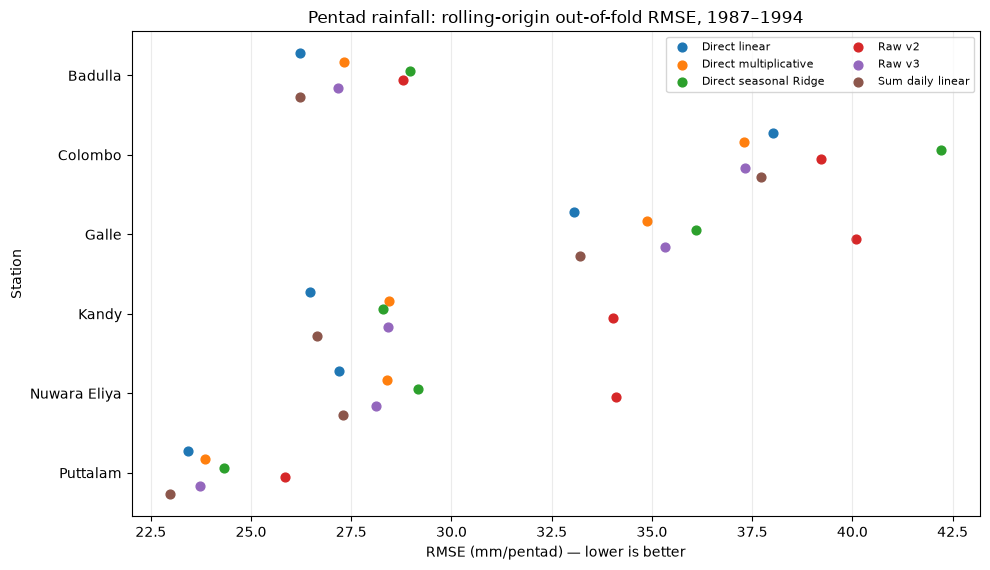


 MONTHLY RMSE units: mm/monthly


Model,Direct linear,Direct multiplicative,Direct seasonal Ridge,Raw v2,Raw v3,Sum daily linear
Station,,,,,,
Badulla,56.75,56.78,69.32,72.97,55.95,65.51
Colombo,76.71,74.41,108.46,93.22,69.33,81.98
Galle,65.22,65.28,101.22,107.74,65.94,81.04
Kandy,40.63,40.65,62.33,83.94,40.82,56.95
Nuwaraeliya,44.64,45.33,74.17,92.12,44.97,61.79
Puttalam,43.49,41.68,65.30,64.48,41.69,44.35


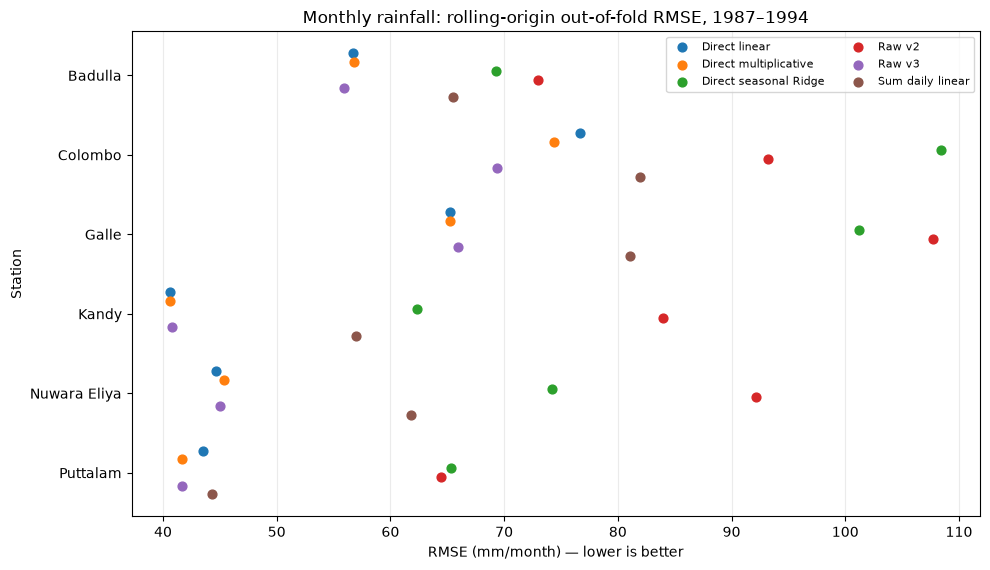

,scale,Station,provisional_model,chosen_RMSE,raw_v3_RMSE,improvement_percent,n_intervals
0,monthly,Badulla,Raw v3,55.953,55.953,0.000,94
1,monthly,Colombo,Raw v3,69.333,69.333,0.000,90
2,monthly,Galle,Direct multiplicative,65.282,65.945,1.004,94
3,monthly,Kandy,Raw v3,40.818,40.818,0.000,95
4,monthly,Nuwaraeliya,Raw v3,44.973,44.973,0.000,89
5,monthly,Puttalam,Raw v3,41.688,41.688,0.000,92
6,pentad,Badulla,Direct linear,26.225,27.163,3.451,520
7,pentad,Colombo,Raw v3,37.315,37.315,0.000,511
8,pentad,Galle,Direct linear,33.058,35.322,6.408,519
9,pentad,Kandy,Direct linear,26.472,28.414,6.834,519


In [9]:
score_rows=[];fold_rows=[]
for (scale,station,model),d in predictions.groupby(['scale','Station','Model']):
    score_rows.append(dict(scale=scale,Station=station,Model=model,**scores(d.Gauge_mm,d.Prediction_mm)))
    for fold,z in d.groupby('fold'):
        fold_rows.append(dict(scale=scale,Station=station,Model=model,fold=fold,**scores(z.Gauge_mm,z.Prediction_mm)))
model_scores=pd.DataFrame(score_rows);fold_scores=pd.DataFrame(fold_rows)
model_scores.to_csv(TABDIR/'03_oof_model_scores.csv',index=False)
fold_scores.to_csv(TABDIR/'04_fold_scores.csv',index=False)
for scale in intervals:
    print('\n',scale.upper(),'RMSE units: mm/'+scale)
    display(model_scores[model_scores.scale.eq(scale)].pivot(index='Station',columns='Model',values='RMSE').round(2))
    fig,ax=plot_rmse_dotplot(model_scores,scale,save_as=f'01_{scale}_RMSE_dotplot');plt.show()

chosen=[]
preference=['Raw v3','Direct multiplicative','Direct linear','Sum daily linear','Direct seasonal Ridge','Raw v2']
for (scale,station),d in model_scores.groupby(['scale','Station']):
    best=d.RMSE.min()
    acceptable=d[d.RMSE<=best*1.01].copy()
    acceptable['simplicity']=acceptable.Model.map({v:i for i,v in enumerate(preference)})
    best_row=acceptable.sort_values(['simplicity','RMSE']).iloc[0]
    raw_rmse=float(d.loc[d.Model.eq('Raw v3'),'RMSE'].iloc[0])
    chosen.append(dict(scale=scale,Station=station,provisional_model=best_row.Model,
                       chosen_RMSE=best_row.RMSE,raw_v3_RMSE=raw_rmse,
                       improvement_percent=100*(raw_rmse-best_row.RMSE)/raw_rmse,
                       n_intervals=best_row.n))
selection=pd.DataFrame(chosen)
selection.to_csv(TABDIR/'05_provisional_station_scale_selection.csv',index=False)
display(selection.round(3))


## 5. Visualization — observed and predicted accumulated rainfall

These time series show whether a correction helps some months but damages peaks or the total rainfall amount. A correlation value near 1 **does not** mean accurate totals.

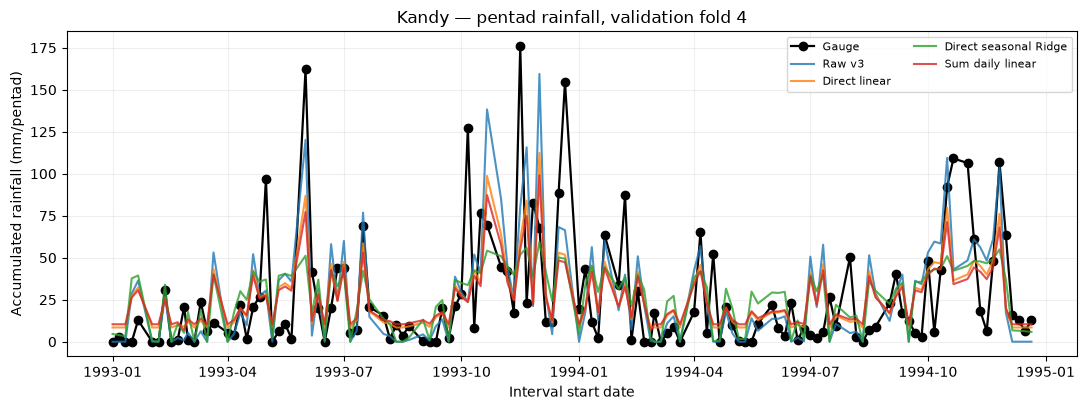

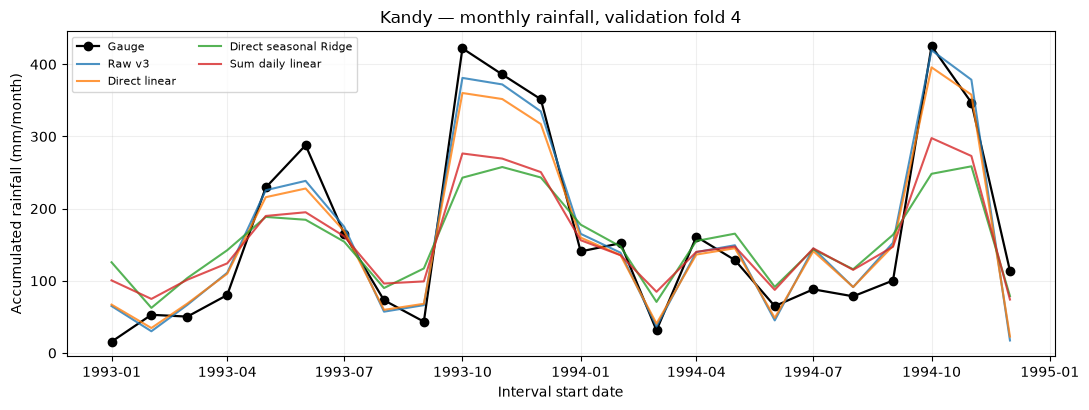

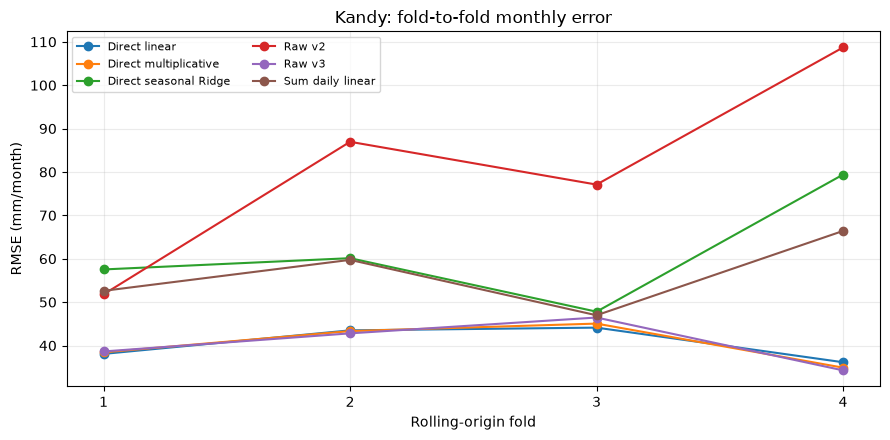

In [11]:
for scale in intervals:
    fig,ax=plot_station_totals(predictions,'Kandy',scale=scale,fold=4,save_as=f'02_Kandy_{scale}_1993_1994')
    plt.show()

def plot_fold_consistency(folds,scale='monthly',station='Kandy',save_as=None):
    d=folds[(folds.scale==scale)&(folds.Station==station)].copy()
    fig,ax=plt.subplots(figsize=(9,4.5))
    for model,z in d.groupby('Model'):
        ax.plot(z.fold,z.RMSE,marker='o',label=model)
    ax.set_xticks([1,2,3,4]);ax.set_xlabel('Rolling-origin fold')
    ax.set_ylabel('RMSE (' + ('mm/month' if scale=='monthly' else 'mm/pentad') + ')');ax.set_title(f'{station}: fold-to-fold {scale} error')
    ax.legend(ncol=2,fontsize=8);ax.grid(alpha=.25);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
fig,ax=plot_fold_consistency(fold_scores,scale='monthly',station='Kandy',save_as='03_Kandy_monthly_fold_consistency');plt.show()


## 6. Why examine stationarity, seasonality and Ljung–Box?

These tests apply to **time-series modelling**, particularly the separate monthly forecasting experiment; they are not prerequisites for the descriptive CHIRPS agreement analysis.

- **ADF:** Null hypothesis of a unit root. A small p-value is evidence against a unit root, **not** proof of full stationarity.
- **KPSS:** Null hypothesis of stationarity around a level (with `regression='c'`). A small p-value is evidence *against* this stationarity null. The two tests may disagree and have low power for short/seasonal series.
- **ACF/PACF:** Identify remaining autocorrelation and candidate autoregressive/seasonal structure; do not select complex models by visual intuition alone. ADF/KPSS/ACF require evenly spaced observations; for exploratory diagnostics, missing *training* months are filled using **training-only month-of-year medians** and this sensitivity must be acknowledged.
- **Ljung–Box Q:** Null is *no residual autocorrelation* at the specified collection of lags. Small p-values signal unresolved serial correlation, not that the forecast model is necessarily worse in RMSE. Degrees-of-freedom adjustment for seasonal models is delicate; inspect `model_df` and interpret as diagnostic.

For month-end missingness, we retain missing observations as NaN in the regular monthly series; for ETS fitting alone, missing **training** months are replaced by training-period month-of-year medians (explicitly labelled). No future gauge values are imputed for scoring or forecast generation.

Kandy training monthly gaps filled for ADF/KPSS/ACF: 3


C:\Users\Asini Perera\AppData\Local\Temp\ipykernel_34668\1345418515.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  z=adfuller(y,autolag='AIC');out.update(ADF_stat=z[0],ADF_p=z[1],ADF_lags=z[2])
C:\Users\Asini Perera\AppData\Local\Temp\ipykernel_34668\1345418515.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  z=adfuller(y,autolag='AIC');out.update(ADF_stat=z[0],

,series,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
0,Kandy monthly gauge (level),144,-7.9538,0.0000,2,0.0509,0.1,5
1,"Kandy monthly gauge (seasonal diff, lag 12)",132,-4.4988,0.0002,13,0.0564,0.1,3


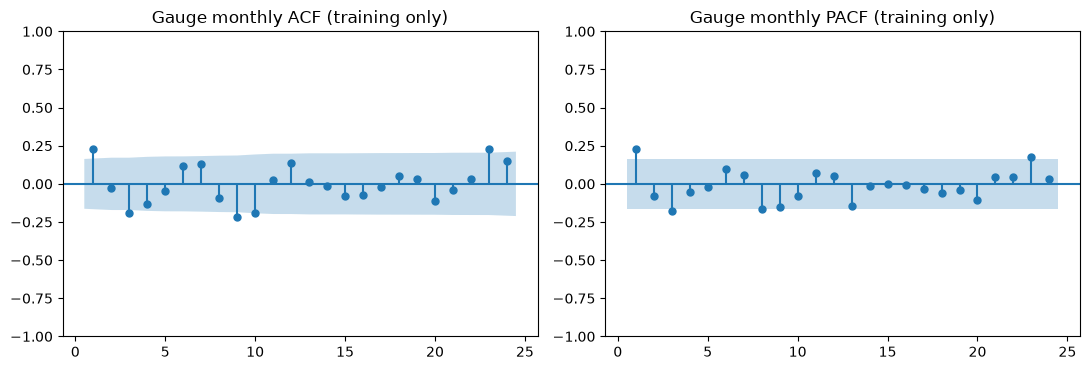

In [13]:
def regular_monthly_gauge(months,station):
    g=months[months.Station==station].set_index('interval').Gauge_mm.sort_index()
    full=pd.date_range('1981-01-01','2000-12-01',freq='MS')
    return g.reindex(full).rename('Gauge_mm')

def stationarity_tests(series):
    y=pd.Series(series).dropna().astype(float)
    out={'n':len(y)}
    if len(y)<30:return out
    try:
        z=adfuller(y,autolag='AIC');out.update(ADF_stat=z[0],ADF_p=z[1],ADF_lags=z[2])
    except Exception as e:out['ADF_error']=str(e)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            z=kpss(y,regression='c',nlags='auto')
        out.update(KPSS_stat=z[0],KPSS_p=z[1],KPSS_lags=z[2])
    except Exception as e:out['KPSS_error']=str(e)
    return out

train_monthly=regular_monthly_gauge(monthly,'Kandy').loc[:'1992-12-01']
# ADF/KPSS and ACF need regular spacing. For this *diagnostic only*, fill
# gaps with month-of-year medians calculated entirely from training years.
# Report that the stationarity results are sensitive to missing-data handling.
train_monthly_regular=train_monthly.copy()
train_medians=train_monthly.groupby(train_monthly.index.month).median()
for missing_date in train_monthly_regular[train_monthly_regular.isna()].index:
    train_monthly_regular.loc[missing_date]=train_medians.loc[missing_date.month]
print('Kandy training monthly gaps filled for ADF/KPSS/ACF:',train_monthly.isna().sum())
stat_tests=pd.DataFrame([
    {'series':'Kandy monthly gauge (level)',**stationarity_tests(train_monthly_regular)},
    {'series':'Kandy monthly gauge (seasonal diff, lag 12)',**stationarity_tests(train_monthly_regular.diff(12))}
])
display(stat_tests.round(4))
stat_tests.to_csv(TABDIR/'06_ADF_KPSS_training_only_Kandy.csv',index=False)

def plot_monthly_acf_pacf(series,save_as=None):
    y=series.dropna()
    fig,axs=plt.subplots(1,2,figsize=(11,3.8))
    lags=min(24,len(y)//2-2)
    plot_acf(y,lags=lags,ax=axs[0],zero=False)
    plot_pacf(y,lags=lags,ax=axs[1],zero=False,method='ywm')
    axs[0].set_title('Gauge monthly ACF (training only)')
    axs[1].set_title('Gauge monthly PACF (training only)')
    fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,axs
fig,axs=plot_monthly_acf_pacf(train_monthly_regular,save_as='04_Kandy_monthly_train_ACF_PACF');plt.show()


## 7. Genuine monthly forecasting baselines — separate, optional experiment

Use **Kandy, fold 4** (train 1981–1992, forecast 1993–1994) for a compact demonstration. By construction, **no same-month CHIRPS or future gauge data enter these predictions**. A 24-month horizon is deliberately harder than repeatedly using each newly observed month to make one-step forecasts.

Baselines:
- **Random walk / persistence:** last observed training gauge monthly total repeated for the entire horizon.
- **Seasonal naive:** reuse the last 12 *training* months in a repeating pattern; never update with actual validation values.
- **ETS:** additive trend-free, additive seasonal smoothing; outputs clipped at zero because rainfall cannot be negative.
- **SARIMA:** `(1,0,0)×(1,0,0,12)` with intercept; illustrative predeclared model, not a validation-optimized order. State-space fitting handles NaNs in training series; do not interpolate the held-out target. Use ADF/KPSS and residual diagnostics to discuss assumptions. Compare on *identical complete validation months*.

Complexity must be justified by out-of-sample scores, not AIC alone. SARIMA can output negative forecasts; here negative estimates are clipped for evaluation, and raw model forecasts are retained for audit.

In [15]:
FORECAST_STATION='Kandy'
FORECAST_FOLD=4
tr_start,tr_end,va_start,va_end=FOLDS[FORECAST_FOLD-1]
yall=regular_monthly_gauge(monthly,FORECAST_STATION)
ytrain=yall.loc[tr_start:tr_end].asfreq('MS')
yvalid=yall.loc[va_start:va_end].asfreq('MS')
H=len(yvalid)
assert H==24 and len(ytrain)>=120
# train-only fill for ETS and last-12 seasonal naive; no values from validation allowed
month_medians=ytrain.groupby(ytrain.index.month).median()
ytrain_filled=ytrain.copy()
for date in ytrain_filled[ytrain_filled.isna()].index:
    ytrain_filled.loc[date]=month_medians.loc[date.month]
assert ytrain_filled.notna().all()
seasonal_last12=ytrain_filled.iloc[-12:].to_numpy()
forecast={
    'Random walk':np.full(H,float(ytrain_filled.iloc[-1])),
    'Seasonal naive':np.resize(seasonal_last12,H)
}
# ETS and SARIMA; fitted strictly on training data
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    ets_fit=ExponentialSmoothing(ytrain_filled,trend=None,seasonal='add',seasonal_periods=12,
                                 initialization_method='estimated').fit(optimized=True)
    forecast['ETS seasonal']=np.maximum(0,np.asarray(ets_fit.forecast(H)))
    sarima_fit=SARIMAX(ytrain,order=(1,0,0),seasonal_order=(1,0,0,12),trend='c',
                       enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=100)
    sarima_raw=np.asarray(sarima_fit.get_forecast(steps=H).predicted_mean)
    forecast['SARIMA seasonal']=np.maximum(0,sarima_raw)

forecast_table=pd.DataFrame({'Date':yvalid.index,'Gauge_mm':yvalid.to_numpy()})
for label,pred in forecast.items():forecast_table[label]=pred
forecast_table.to_csv(TABDIR/'07_Kandy_gauge_only_24month_forecast.csv',index=False)
rows=[]
for label in forecast:
    rows.append(dict(Model=label,**scores(yvalid,forecast_table[label])))
forecast_scores=pd.DataFrame(rows)
forecast_scores.to_csv(TABDIR/'08_gauge_only_forecast_scores.csv',index=False)
print('Forecast origin:',tr_end,'Horizon:',H,'months','Valid scored months:',yvalid.notna().sum())
display(forecast_scores.round(3))
print('SARIMA optimizer converged:',sarima_fit.mle_retvals.get('converged'))


Forecast origin: 1992-12-31 Horizon: 24 months Valid scored months: 24


,Model,n,RMSE,MAE,Bias,Pearson_r,Spearman_rho,NRMSE_percent
0,Random walk,24,157.114,106.817,-89.942,NaN,NaN,94.509
1,Seasonal naive,24,115.729,94.850,-39.942,0.564,0.535,69.615
2,ETS seasonal,24,97.655,78.367,-17.108,0.739,0.654,58.743
3,SARIMA seasonal,24,124.788,98.622,-16.926,0.451,0.443,75.064


SARIMA optimizer converged: True


## 8. SARIMA residual diagnostics — Ljung–Box, ACF, histogram, QQ

**Ljung–Box:** \(H_0\): no autocorrelation in residuals through lag \(h\). We test lag 12 and optionally 24 if the residual length allows; these p-values do **not** test stationarity, normality or rainfall accuracy. A p-value below 0.05 is evidence of residual autocorrelation; above 0.05 means insufficient evidence to reject, not proof of white noise. Seasonal AR terms require degrees-of-freedom care; this notebook uses a conservative `model_df=2` as an exploratory adjustment and shows the settings explicitly.

**Important:** residual diagnostics inspect *in-sample fitted model innovations* after a burn-in. Out-of-sample forecast error is measured separately above; diagnostics do not replace forecast validation.

,lag,Ljung_Box_Q,p_value,n_residuals,model_df_adjustment
0,12,17.6120,0.0619,128,2
1,24,31.9136,0.0789,128,2


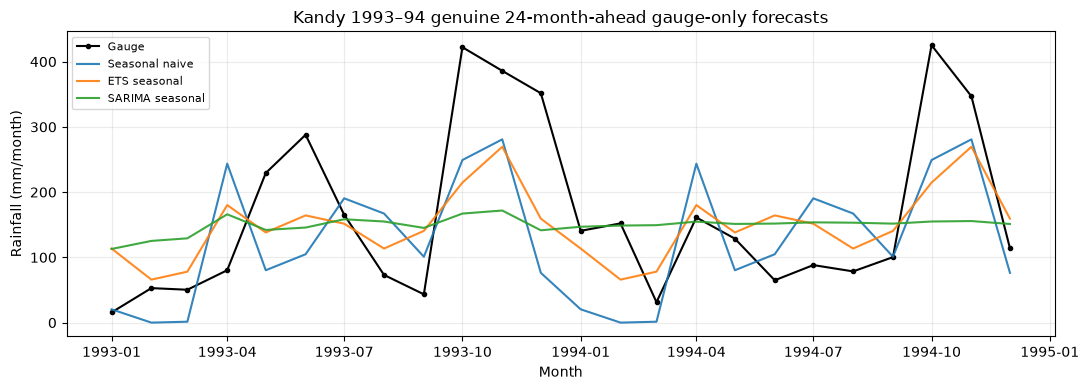

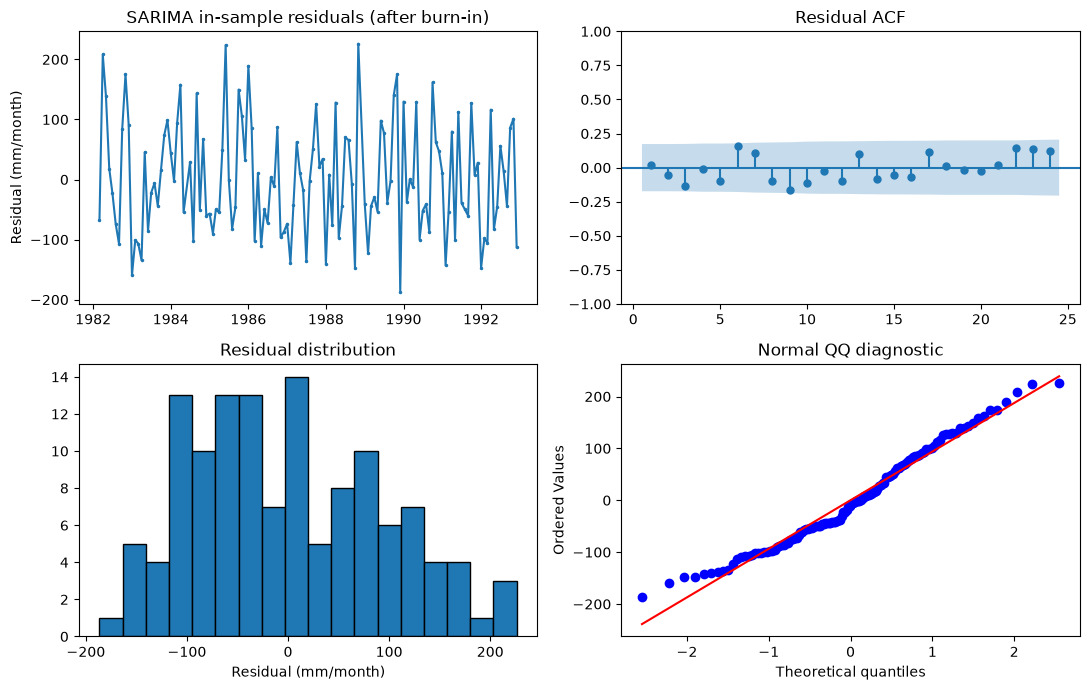

In [17]:
def ljung_box_diagnostic(fit,lag_list=(12,24),model_df=2,burnin=13):
    res=pd.Series(np.asarray(fit.resid),index=fit.model.data.row_labels).iloc[burnin:]
    res=res.dropna()
    lags=[lag for lag in lag_list if lag>model_df and lag<len(res)//2]
    if not lags:raise ValueError('Not enough residuals for requested lags')
    lb=acorr_ljungbox(res,lags=lags,model_df=model_df,return_df=True)
    lb=lb.reset_index().rename(columns={'index':'lag','lb_stat':'Ljung_Box_Q','lb_pvalue':'p_value'})
    lb['n_residuals']=len(res);lb['model_df_adjustment']=model_df
    return lb,res

lb_table,resid=ljung_box_diagnostic(sarima_fit)
display(lb_table.round(4))
lb_table.to_csv(TABDIR/'09_Kandy_SARIMA_Ljung_Box.csv',index=False)

def plot_forecast_and_residuals(forecast_table,residuals,save_as=None):
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(forecast_table.Date,forecast_table.Gauge_mm,'ko-',label='Gauge',markersize=3)
    for c in ['Seasonal naive','ETS seasonal','SARIMA seasonal']:
        ax.plot(forecast_table.Date,forecast_table[c],label=c,alpha=.9)
    ax.set_title('Kandy 1993–94 genuine 24-month-ahead gauge-only forecasts')
    ax.set_ylabel('Rainfall (mm/month)');ax.set_xlabel('Month');ax.legend(fontsize=8)
    ax.grid(alpha=.25);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    fig2,axes=plt.subplots(2,2,figsize=(11,7))
    axes[0,0].plot(residuals.index,residuals,'.-',markersize=3)
    axes[0,0].set_title('SARIMA in-sample residuals (after burn-in)')
    axes[0,0].set_ylabel('Residual (mm/month)')
    plot_acf(residuals,lags=min(24,len(residuals)//2-2),ax=axes[0,1],zero=False)
    axes[0,1].set_title('Residual ACF')
    axes[1,0].hist(residuals,bins=18,edgecolor='black');axes[1,0].set_title('Residual distribution')
    axes[1,0].set_xlabel('Residual (mm/month)')
    stats.probplot(residuals,dist='norm',plot=axes[1,1]);axes[1,1].set_title('Normal QQ diagnostic')
    fig2.tight_layout()
    if save_as:save_fig(fig2,save_as+'_residuals')
    return (fig,ax),(fig2,axes)

plots=plot_forecast_and_residuals(forecast_table,resid,save_as='05_Kandy_forecasting_and_SARIMA_diagnostics')
plt.show()


## 9. Model assumptions and conclusions — interpret, do not overclaim

**Calibration:** For each station compare the monthly and pentad `Raw v3`, `Direct linear`, `Direct multiplicative`, `Direct seasonal Ridge`, and `Sum daily linear` on identical intervals. **Smaller pentad RMSE and monthly RMSE are not directly comparable in magnitude** because each measures a different accumulation interval. Direct calibration conditions on interval CHIRPS availability; it is not a next-month forecast. Report poor or negative improvements explicitly.

**Time series:** ADF and KPSS have different null hypotheses. If residual Ljung–Box p-values are small, the stated SARIMA specification still contains serial structure. This need not disqualify its use as an exploratory baseline but should be reported. SARIMA forecasts depend on the start date and forecast horizon; repeated monthly forecast updating would constitute a different experiment.

**Statistical uncertainty:** Four chronological validation folds are not four independent climate realizations. Do not claim formal significance from the 1% selection rule or fold variability. The final 1995–2000 historical evaluation is reserved for Notebook 06 and was previously viewed in exploratory work.

**Next notebooks:** Notebook 05 adds ERA5 humidity/wind and DEM terrain features by controlled ablation; Notebook 06 makes station-specific selections across daily, pentad and monthly objectives and reports test-period sensitivity and limitations.

### Reproducibility and literature
- University of Colombo PH3043 project brief — compulsory chronological validation and error metrics.
- Funk et al. (2015), CHIRPS v2, https://doi.org/10.1038/sdata.2015.66
- Funk et al. (2026), CHIRPS v3, https://doi.org/10.1038/s41597-026-07096-4
- CHC official v3 methodology: https://www.chc.ucsb.edu/data/chirps3 — RNL uses ERA5 to partition pentad totals.
- Hyndman and Athanasopoulos, *Forecasting: Principles and Practice*: https://otexts.com/fpp3/
- `statsmodels` Ljung–Box reference: https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html
- statsmodels SARIMAX: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html


## 10. Automatic evidence summary and notebook check

Use the printed results to write a final scientific paragraph. Do not call the selected candidates final; Notebook 06 performs the historical evaluation.

In [18]:
for scale in ['pentad','monthly']:
    a=selection[selection.scale.eq(scale)]
    print(f'\n{scale.upper()} (RMSE in mm/{scale}) — provisional candidates')
    print(a[['Station','provisional_model','raw_v3_RMSE','chosen_RMSE','improvement_percent','n_intervals']].round(3).to_string(index=False))

print('\nSARIMA diagnostics:')
for _,z in lb_table.iterrows():
    print('lag',int(z.lag),'p=',round(z.p_value,4),
          ': possible residual autocorrelation' if z.p_value<0.05 else ': insufficient evidence to reject no autocorrelation')
print('\nOutput directory:',OUT)
print('Python code cells complete. No 1995–2000 gauge observations used for model fitting/selection.')



PENTAD (RMSE in mm/pentad) — provisional candidates
    Station provisional_model  raw_v3_RMSE  chosen_RMSE  improvement_percent  n_intervals
    Badulla     Direct linear       27.163       26.225                3.451          520
    Colombo            Raw v3       37.315       37.315                0.000          511
      Galle     Direct linear       35.322       33.058                6.408          519
      Kandy     Direct linear       28.414       26.472                6.834          519
Nuwaraeliya     Direct linear       28.124       27.191                3.315          513
   Puttalam  Sum daily linear       23.725       22.984                3.126          518

MONTHLY (RMSE in mm/monthly) — provisional candidates
    Station     provisional_model  raw_v3_RMSE  chosen_RMSE  improvement_percent  n_intervals
    Badulla                Raw v3       55.953       55.953                0.000           94
    Colombo                Raw v3       69.333       69.333               

In [24]:

# ============================================================
# NOTEBOOK 04 — IMPROVEMENT 1
# Paired year-block bootstrap of RMSE improvement
# Rolling-origin validation: 1987–1994
# ============================================================

def rmse(gauge, predicted):
    g = np.asarray(gauge, dtype=float)
    p = np.asarray(predicted, dtype=float)
    valid = np.isfinite(g) & np.isfinite(p)
    return np.sqrt(np.mean((p[valid] - g[valid])**2))


def bootstrap_scale_improvements(
    predictions,
    selection,
    n_boot=5000,
    seed=42
):
    rng = np.random.default_rng(seed)
    rows = []

    for _, selected in selection.iterrows():

        station = selected["Station"]
        scale = selected["scale"]
        chosen_model = selected["provisional_model"]

        d = predictions[
            (predictions["Station"] == station) &
            (predictions["scale"] == scale)
        ].copy()

        # Reference predictions
        raw = d[d["Model"] == "Raw v3"][
            ["fold", "interval", "Gauge_mm", "Prediction_mm"]
        ].rename(columns={
            "Prediction_mm": "Raw_prediction"
        })

        # Selected-model predictions
        calibrated = d[d["Model"] == chosen_model][
            ["fold", "interval", "Gauge_mm", "Prediction_mm"]
        ].rename(columns={
            "Gauge_mm": "Gauge_selected",
            "Prediction_mm": "Selected_prediction"
        })

        # Match by validation fold AND interval
        paired = raw.merge(
            calibrated,
            on=["fold", "interval"],
            how="inner",
            validate="one_to_one"
        )

        assert len(paired) == len(raw)
        assert np.allclose(
            paired["Gauge_mm"],
            paired["Gauge_selected"]
        )

        paired["Year"] = pd.to_datetime(
            paired["interval"]
        ).dt.year

        paired = paired.dropna(subset=[
            "Gauge_mm",
            "Raw_prediction",
            "Selected_prediction"
        ])

        observed_raw = rmse(
            paired["Gauge_mm"],
            paired["Raw_prediction"]
        )

        observed_selected = rmse(
            paired["Gauge_mm"],
            paired["Selected_prediction"]
        )

        observed_difference = (
            observed_raw - observed_selected
        )

        # Resample entire calendar-year blocks
        blocks = [
            block.copy()
            for _, block in paired.groupby("Year")
        ]

        n_years = len(blocks)
        boot_differences = np.empty(n_boot)

        for b in range(n_boot):

            sampled_indices = rng.integers(
                0, n_years, size=n_years
            )

            sample = pd.concat(
                [blocks[i] for i in sampled_indices],
                ignore_index=True
            )

            raw_b = rmse(
                sample["Gauge_mm"],
                sample["Raw_prediction"]
            )

            selected_b = rmse(
                sample["Gauge_mm"],
                sample["Selected_prediction"]
            )

            boot_differences[b] = raw_b - selected_b

        ci_low, ci_high = np.quantile(
            boot_differences, [0.025, 0.975]
        )

        rows.append({
            "Station": station,
            "scale": scale,
            "Selected_model": chosen_model,
            "n_intervals": len(paired),
            "n_year_blocks": n_years,
            "Raw_RMSE": observed_raw,
            "Selected_RMSE": observed_selected,
            "RMSE_reduction": observed_difference,
            "Improvement_percent":
                100 * observed_difference / observed_raw,
            "CI_lower": ci_low,
            "CI_upper": ci_high,
            "CI_entirely_positive": ci_low > 0
        })

    return pd.DataFrame(rows)


uncertainty_results = bootstrap_scale_improvements(
    predictions,
    selection,
    n_boot=5000,
    seed=42
)

display(uncertainty_results.round(3))

uncertainty_results.to_csv(
    TABDIR / "06_RMSE_uncertainty_bootstrap.csv",
    index=False
)


,Station,scale,Selected_model,n_intervals,n_year_blocks,Raw_RMSE,Selected_RMSE,RMSE_reduction,Improvement_percent,CI_lower,CI_upper,CI_entirely_positive
0,Badulla,monthly,Raw v3,94,8,55.953,55.953,0.000,0.000,0.000,0.000,False
1,Colombo,monthly,Raw v3,90,8,69.333,69.333,0.000,0.000,0.000,0.000,False
2,Galle,monthly,Direct multiplicative,94,8,65.945,65.282,0.662,1.004,-1.952,3.251,False
3,Kandy,monthly,Raw v3,95,8,40.818,40.818,0.000,0.000,0.000,0.000,False
4,Nuwaraeliya,monthly,Raw v3,89,8,44.973,44.973,0.000,0.000,0.000,0.000,False
5,Puttalam,monthly,Raw v3,92,8,41.688,41.688,0.000,0.000,0.000,0.000,False
6,Badulla,pentad,Direct linear,520,8,27.163,26.225,0.937,3.451,-0.049,1.712,False
7,Colombo,pentad,Raw v3,511,8,37.315,37.315,0.000,0.000,0.000,0.000,False
8,Galle,pentad,Direct linear,519,8,35.322,33.058,2.263,6.408,0.747,3.838,True
9,Kandy,pentad,Direct linear,519,8,28.414,26.472,1.942,6.834,1.105,2.846,True


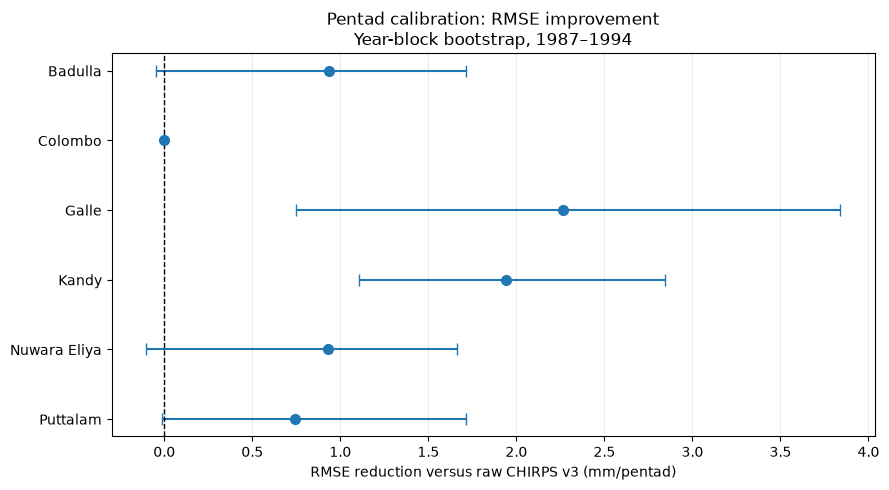

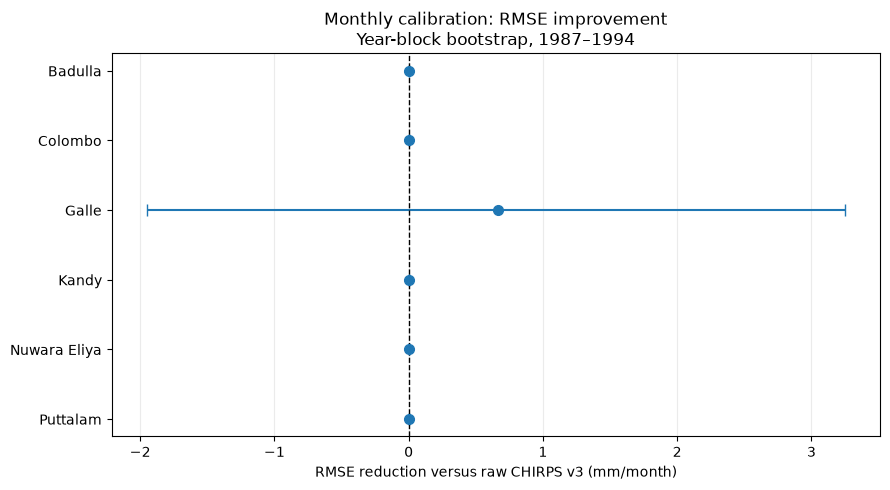

In [25]:

def plot_rmse_uncertainty(results, scale, save_as=None):

    d = results[
        results["scale"] == scale
    ].set_index("Station").reindex(STATIONS)

    fig, ax = plt.subplots(figsize=(9, 5))

    y = np.arange(len(d))
    effect = d["RMSE_reduction"].to_numpy(float)

    low = d["CI_lower"].to_numpy(float)
    high = d["CI_upper"].to_numpy(float)

    # Asymmetric confidence intervals
    error = np.vstack([
        np.maximum(effect - low, 0),
        np.maximum(high - effect, 0)
    ])

    ax.errorbar(
        effect,
        y,
        xerr=error,
        fmt="o",
        capsize=4,
        markersize=7
    )

    ax.axvline(
        0, linestyle="--",
        color="black", linewidth=1
    )

    ax.set_yticks(y)

    ax.set_yticklabels([
        "Nuwara Eliya" if s == "Nuwaraeliya" else s
        for s in STATIONS
    ])

    ax.invert_yaxis()

    unit = (
        "mm/month" if scale == "monthly"
        else "mm/pentad"
    )

    ax.set_xlabel(
        f"RMSE reduction versus raw CHIRPS v3 ({unit})"
    )

    ax.set_title(
        f"{scale.capitalize()} calibration: RMSE improvement\n"
        "Year-block bootstrap, 1987–1994"
    )

    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()

    if save_as:
        save_fig(fig, save_as)

    return fig, ax


for scale in ["pentad", "monthly"]:
    fig, ax = plot_rmse_uncertainty(
        uncertainty_results,
        scale=scale,
        save_as=f"04_{scale}_RMSE_uncertainty"
    )
    plt.show()


Improvement 2 — Check consistency across the four validation folds
Suppose a model reduces pooled RMSE by 5%. We should check whether it improves performance consistently, or whether one unusually good validation period produces most of the apparent benefit.

Your notebook already calculates fold_scores, so we do not need to refit anything.
Step 3: Add the fold-consistency summary
Insert a new code cell below the bootstrap plots.

In [29]:

# ============================================================
# NOTEBOOK 04 — IMPROVEMENT 2
# Fold-by-fold comparison with raw CHIRPS v3
# ============================================================

def compare_selected_models_by_fold(fold_scores, selection):

    rows = []

    for _, selected in selection.iterrows():

        station = selected["Station"]
        scale = selected["scale"]
        model = selected["provisional_model"]

        d = fold_scores[
            (fold_scores["Station"] == station) &
            (fold_scores["scale"] == scale)
        ]

        raw = d[d["Model"] == "Raw v3"][
            ["fold", "RMSE", "n"]
        ].rename(columns={
            "RMSE": "Raw_RMSE",
            "n": "Raw_n"
        })

        chosen = d[d["Model"] == model][
            ["fold", "RMSE", "n"]
        ].rename(columns={
            "RMSE": "Selected_RMSE",
            "n": "Selected_n"
        })

        comparison = raw.merge(
            chosen,
            on="fold",
            validate="one_to_one"
        )

        assert (
            comparison["Raw_n"] ==
            comparison["Selected_n"]
        ).all()

        comparison["RMSE_reduction"] = (
            comparison["Raw_RMSE"] -
            comparison["Selected_RMSE"]
        )

        comparison["Improvement_percent"] = (
            100 * comparison["RMSE_reduction"]
            / comparison["Raw_RMSE"]
        )

        comparison["Station"] = station
        comparison["scale"] = scale
        comparison["Selected_model"] = model

        rows.append(comparison)

    return pd.concat(rows, ignore_index=True)


fold_comparison = compare_selected_models_by_fold(
    fold_scores,
    selection
)

fold_summary = (
    fold_comparison
    .groupby(["scale", "Station", "Selected_model"])
    .agg(
        n_folds=("fold", "count"),
        folds_improved=(
            "RMSE_reduction",
            lambda x: int((x > 1e-9).sum())
        ),
        folds_worsened=(
            "RMSE_reduction",
            lambda x: int((x < -1e-9).sum())
        ),
        mean_improvement_percent=(
            "Improvement_percent", "mean"
        ),
        min_improvement_percent=(
            "Improvement_percent", "min"
        ),
        max_improvement_percent=(
            "Improvement_percent", "max"
        )
    )
    .reset_index()
)

display(fold_comparison.round(3))
display(fold_summary.round(3))

fold_comparison.to_csv(
    TABDIR / "07_fold_by_fold_comparison.csv",
    index=False
)

fold_summary.to_csv(
    TABDIR / "08_fold_consistency_summary.csv",
    index=False
)


,fold,Raw_RMSE,Raw_n,Selected_RMSE,Selected_n,RMSE_reduction,Improvement_percent,Station,scale,Selected_model
0,1,57.024,23,57.024,23,0.000,0.000,Badulla,monthly,Raw v3
1,2,44.217,23,44.217,23,0.000,0.000,Badulla,monthly,Raw v3
2,3,57.054,24,57.054,24,0.000,0.000,Badulla,monthly,Raw v3
3,4,63.381,24,63.381,24,0.000,0.000,Badulla,monthly,Raw v3
4,1,75.051,22,75.051,22,0.000,0.000,Colombo,monthly,Raw v3
5,2,70.105,21,70.105,21,0.000,0.000,Colombo,monthly,Raw v3
6,3,67.455,24,67.455,24,0.000,0.000,Colombo,monthly,Raw v3
7,4,64.709,23,64.709,23,0.000,0.000,Colombo,monthly,Raw v3
8,1,55.010,24,53.513,24,1.498,2.723,Galle,monthly,Direct multiplicative
9,2,59.383,22,61.912,22,-2.529,-4.259,Galle,monthly,Direct multiplicative


,scale,Station,Selected_model,n_folds,folds_improved,folds_worsened,mean_improvement_percent,min_improvement_percent,max_improvement_percent
0,monthly,Badulla,Raw v3,4,0,0,0.000,0.000,0.000
1,monthly,Colombo,Raw v3,4,0,0,0.000,0.000,0.000
2,monthly,Galle,Direct multiplicative,4,3,1,0.646,-4.259,2.723
3,monthly,Kandy,Raw v3,4,0,0,0.000,0.000,0.000
4,monthly,Nuwaraeliya,Raw v3,4,0,0,0.000,0.000,0.000
5,monthly,Puttalam,Raw v3,4,0,0,0.000,0.000,0.000
6,pentad,Badulla,Direct linear,4,4,0,3.536,0.300,5.948
7,pentad,Colombo,Raw v3,4,0,0,0.000,0.000,0.000
8,pentad,Galle,Direct linear,4,4,0,6.438,3.850,9.225
9,pentad,Kandy,Direct linear,4,4,0,7.472,2.594,14.371


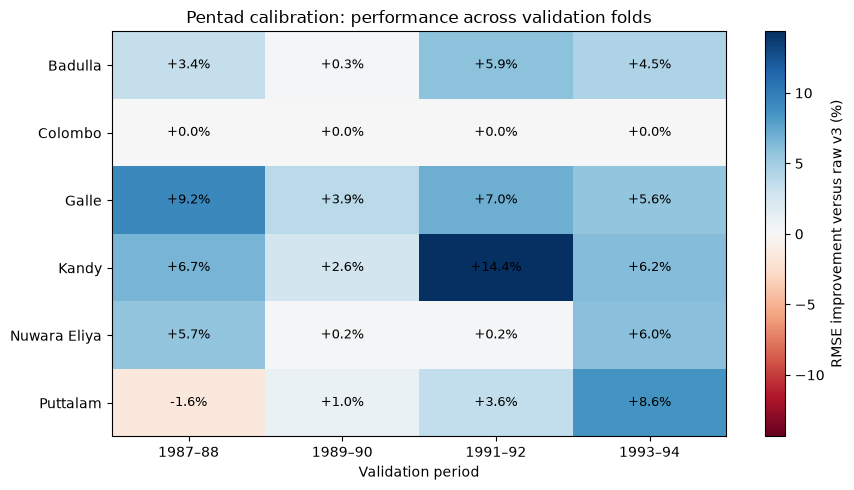

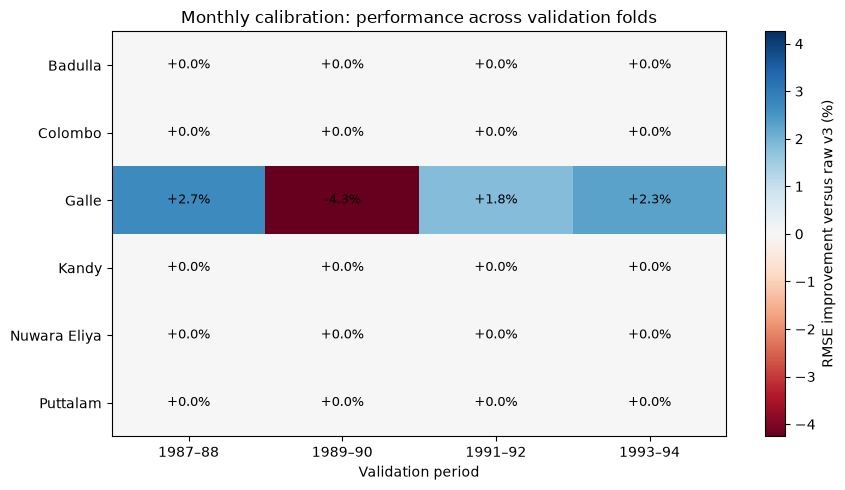

In [31]:

def plot_fold_improvement_heatmap(
    fold_comparison,
    scale="pentad",
    save_as=None
):

    d = fold_comparison[
        fold_comparison["scale"] == scale
    ]

    table = (
        d.pivot(
            index="Station",
            columns="fold",
            values="Improvement_percent"
        )
        .reindex(index=STATIONS, columns=[1, 2, 3, 4])
    )

    values = table.to_numpy(float)
    max_abs = np.nanmax(np.abs(values))
    max_abs = max(max_abs, 1.0)

    fig, ax = plt.subplots(figsize=(9, 5))

    im = ax.imshow(
        values,
        cmap="RdBu",
        vmin=-max_abs,
        vmax=max_abs,
        aspect="auto"
    )

    ax.set_xticks(range(4))
    ax.set_xticklabels([
        "1987–88",
        "1989–90",
        "1991–92",
        "1993–94"
    ])

    ax.set_yticks(range(len(STATIONS)))
    ax.set_yticklabels([
        "Nuwara Eliya" if s == "Nuwaraeliya" else s
        for s in STATIONS
    ])

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]

            if np.isfinite(value):
                ax.text(
                    j, i,
                    f"{value:+.1f}%",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=9
                )

    fig.colorbar(
        im,
        ax=ax,
        label="RMSE improvement versus raw v3 (%)"
    )

    ax.set_title(
        f"{scale.capitalize()} calibration: "
        "performance across validation folds"
    )

    ax.set_xlabel("Validation period")
    fig.tight_layout()

    if save_as:
        save_fig(fig, save_as)

    return fig, ax


for scale in ["pentad", "monthly"]:
    fig, ax = plot_fold_improvement_heatmap(
        fold_comparison,
        scale=scale,
        save_as=f"05_{scale}_fold_consistency"
    )
    plt.show()


## Final Scientific Conclusion — Notebook 04

This investigation evaluated whether direct calibration of CHIRPS v3 RNL rainfall at pentad and monthly timescales improves accumulated rainfall estimates relative to raw CHIRPS and sums of daily corrected values. Models were evaluated using four expanding-window validation folds covering 1987–1994.

**Pentad calibration:** Direct linear calibration was retained at Badulla, Galle, Kandy and Nuwara Eliya, reducing pentad RMSE by approximately 3.32–6.83% relative to raw CHIRPS v3 RNL. Puttalam showed a 3.13% improvement from accumulating daily linear corrections, whereas uncorrected v3 was retained at Colombo. These results suggest that the preferred correction strategy depends on the station and accumulation scale.

**Monthly calibration:** Raw CHIRPS v3 RNL remained the preferred candidate at five stations under the predefined model-selection rule. At Galle, direct multiplicative calibration provided a small improvement of approximately 1.00%. The results indicate that additional monthly correction is not necessarily beneficial when the uncorrected product already represents accumulated rainfall reasonably well.

**Stationarity and forecasting:** For Kandy monthly rainfall, ADF and KPSS diagnostics were compatible with level stationarity under their respective assumptions. In a separate 24-month-ahead gauge-only forecasting demonstration, seasonal exponential smoothing achieved lower RMSE than the tested persistence, seasonal-naive and SARIMA models. Ljung–Box diagnostics for the SARIMA residuals did not reject the no-autocorrelation null at lags 12 and 24 at the 5% significance level.

**Overall conclusion:** The results provide descriptive evidence that scale-specific calibration can improve pentad rainfall estimates at selected stations, but monthly calibration offers smaller and less consistent benefits. Model choice should therefore depend on temporal resolution and station characteristics rather than assuming that the best daily correction will also produce the most accurate accumulated totals.

These findings are based on rolling-origin development-period evaluation and require further uncertainty assessment and historical evaluation. The forecasting experiment is separate from retrospective satellite-rainfall calibration and should not be interpreted as a direct comparison under identical information availability.

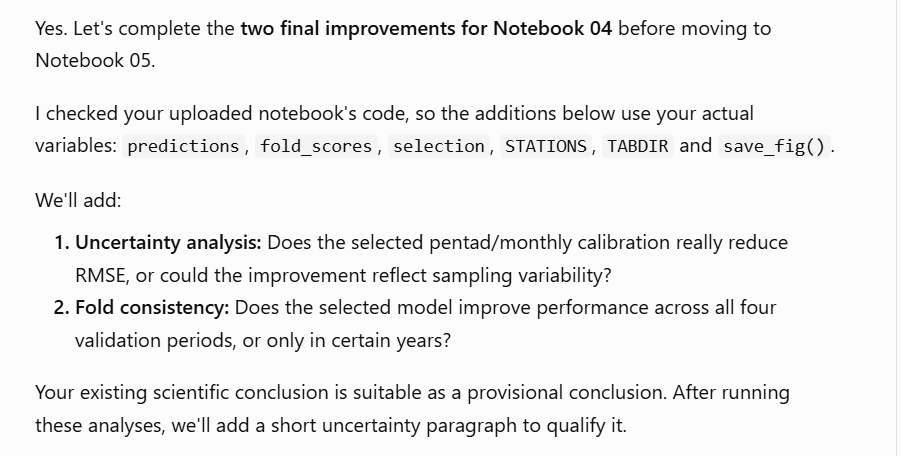

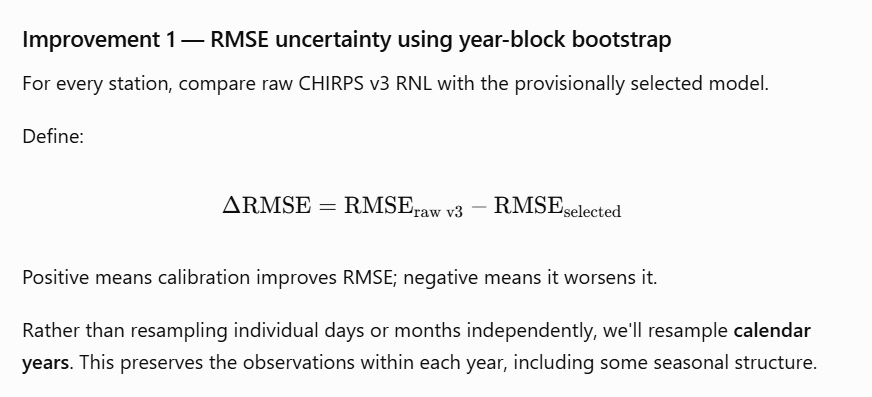

### Uncertainty and Temporal Consistency of Pentad and Monthly Calibration

The reliability of scale-specific rainfall calibration was examined using four expanding-window validation folds over 1987–1994 and paired calendar-year block bootstrap resampling. The primary comparison was the reduction in RMSE relative to uncorrected CHIRPS v3 RNL, with positive values indicating improved rainfall estimation. Bootstrap intervals were calculated using 5,000 resamples of calendar-year blocks.

**Pentad calibration:** The selected corrections reduced pentad RMSE in all four validation folds at Badulla, Galle, Kandy and Nuwara Eliya. Galle exhibited improvements of approximately 3.9–9.2% across folds, while Kandy showed larger variability, with improvements ranging from 2.6% to 14.4%. Their exploratory 95% bootstrap intervals for RMSE reduction remained above zero, providing comparatively stronger evidence of a calibration benefit. In contrast, the intervals for Badulla and Nuwara Eliya crossed zero, indicating that their observed RMSE reductions were less robust to annual resampling. Puttalam improved in three of four folds, but its bootstrap interval approached zero, suggesting uncertain benefits. At Colombo, raw CHIRPS v3 RNL was retained and therefore produced a zero difference by construction.

**Monthly calibration:** Raw CHIRPS v3 RNL was retained at five of six stations under the predefined model-selection rule. At Galle, direct multiplicative calibration yielded a small pooled RMSE improvement of approximately 0.66 mm/month. However, its fold-level performance was inconsistent, including a 4.3% deterioration during 1989–1990. The bootstrap interval also crossed zero, indicating that the available evidence does not establish a reliable monthly calibration benefit.

**Scientific interpretation:** These findings suggest that direct pentad calibration may offer a more reproducible improvement than monthly calibration at selected stations, particularly Galle and Kandy. Nevertheless, the improvements vary by station and historical period. The results support retaining raw CHIRPS v3 RNL when calibration fails to provide a meaningful and sufficiently consistent advantage.

**Statistical limitations:** All bootstrap intervals are exploratory and conditional on model selection, because the same rolling-validation predictions informed both model selection and uncertainty estimation. The eight annual blocks provide limited independent information, and the intervals do not fully account for uncertainty introduced by selecting among multiple candidate models. In addition, stations where raw CHIRPS was retained were compared with themselves; zero-width intervals should not be interpreted as proof that all alternatives are inferior.

**Conclusion:** The combined fold-level and bootstrap analyses provide stronger exploratory support for pentad calibration at Galle and Kandy, but do not establish a consistently beneficial monthly correction at any station. Final recommendations require evaluation of the frozen procedures on the later historical period, with the previously explored nature of that period explicitly acknowledged.

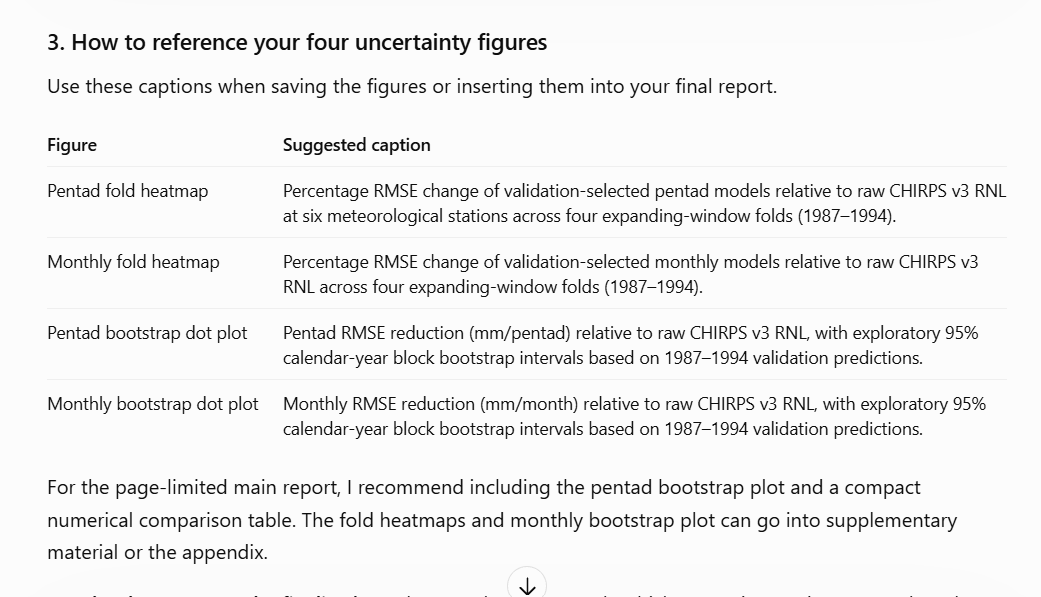